In [1]:
import zipfile

with zipfile.ZipFile('/content/house-prices-advanced-regression-techniques.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/house_prices')

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
sns.set_theme(style="whitegrid")

In [4]:
df = pd.read_csv('/content/house_prices/train.csv')

In [5]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
df.shape

(1460, 81)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [8]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [9]:
df.describe(include='object')

,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
count,1460,1460,91,1460,1460,1460,1460,1460,1460,1460,...,1379,1379,1379,1379,1460,7,281,54,1460,1460
unique,5,2,2,4,4,2,5,3,25,9,...,6,3,5,5,3,3,4,4,9,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,Gd,MnPrv,Shed,WD,Normal
freq,1151,1454,50,925,1311,1459,1052,1382,225,1260,...,870,605,1311,1326,1340,3,157,49,1267,1198


In [10]:
len(df.columns)

81

In [11]:
df.columns.tolist()

['Id',
 'MSSubClass',
 'MSZoning',
 'LotFrontage',
 'LotArea',
 'Street',
 'Alley',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'OverallQual',
 'OverallCond',
 'YearBuilt',
 'YearRemodAdd',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'MasVnrArea',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinSF1',
 'BsmtFinType2',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'TotalBsmtSF',
 'Heating',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 '1stFlrSF',
 '2ndFlrSF',
 'LowQualFinSF',
 'GrLivArea',
 'BsmtFullBath',
 'BsmtHalfBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'KitchenQual',
 'TotRmsAbvGrd',
 'Functional',
 'Fireplaces',
 'FireplaceQu',
 'GarageType',
 'GarageYrBlt',
 'GarageFinish',
 'GarageCars',
 'GarageArea',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'WoodDeckSF',
 'OpenPorchSF'

In [12]:
df.dtypes.value_counts()

,count
object,43
int64,35
float64,3


In [13]:
'SalePrice' in df.columns

True

In [14]:
df['Id'].head()

,Id
0,1
1,2
2,3
3,4
4,5


In [15]:
df.isnull().sum()

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,259
LotArea,0
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


In [16]:
df.isnull().sum().sum()

np.int64(7829)

In [17]:
(df.isnull().mean() * 100).sort_values(ascending=False)

,0
PoolQC,99.520548
MiscFeature,96.301370
Alley,93.767123
Fence,80.753425
MasVnrType,59.726027
...,...
MoSold,0.000000
YrSold,0.000000
SaleType,0.000000
SaleCondition,0.000000


In [18]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': df.isnull().mean() * 100
})

In [19]:
missing = missing[missing['Missing_Count'] > 0]

In [20]:
missing = missing.sort_values(
    by='Missing_Percentage',
    ascending=False
)

In [21]:
missing

,Missing_Count,Missing_Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


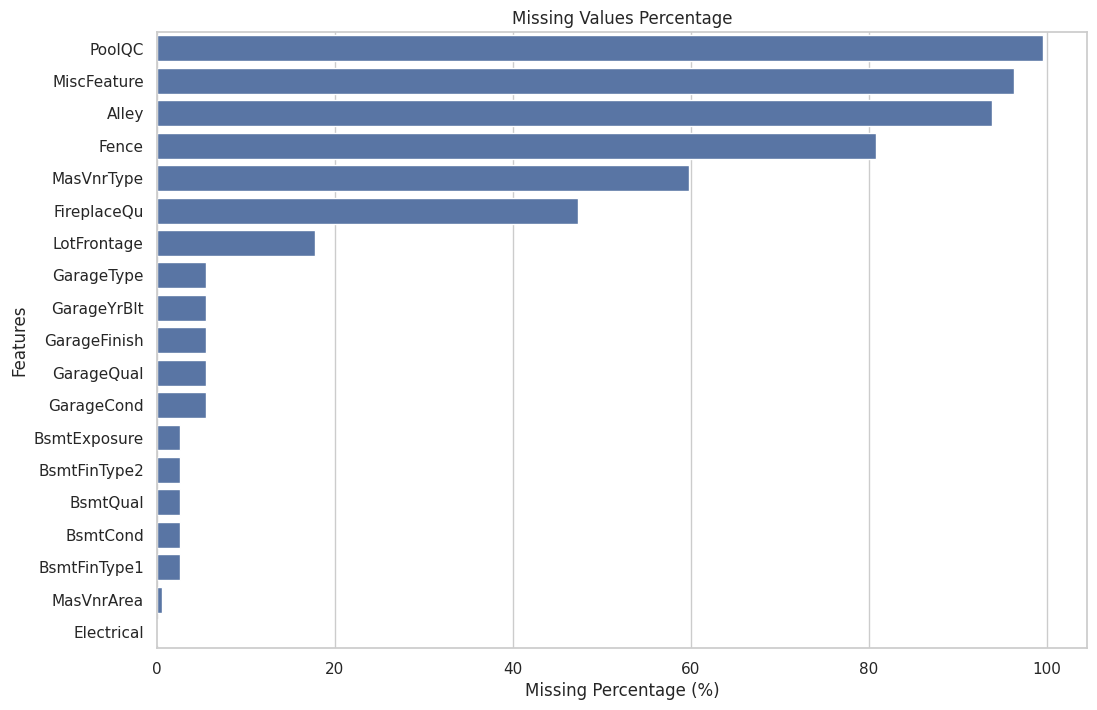

In [22]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=missing.reset_index(),
    x='Missing_Percentage',
    y='index'
)

plt.title('Missing Values Percentage')
plt.xlabel('Missing Percentage (%)')
plt.ylabel('Features')
plt.show()

In [23]:
missing.index.tolist()

['PoolQC',
 'MiscFeature',
 'Alley',
 'Fence',
 'MasVnrType',
 'FireplaceQu',
 'LotFrontage',
 'GarageType',
 'GarageYrBlt',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'BsmtExposure',
 'BsmtFinType2',
 'BsmtQual',
 'BsmtCond',
 'BsmtFinType1',
 'MasVnrArea',
 'Electrical']

In [24]:
df['PoolQC'].value_counts(dropna=False)

,count
PoolQC,
NaN,1453
Gd,3
Ex,2
Fa,2


In [25]:
df['GarageType'].value_counts(dropna=False)

,count
GarageType,
Attchd,870
Detchd,387
BuiltIn,88
NaN,81
Basment,19
CarPort,9
2Types,6


In [26]:
df['BsmtQual'].value_counts(dropna=False)

,count
BsmtQual,
TA,649
Gd,618
Ex,121
NaN,37
Fa,35


In [27]:
df['FireplaceQu'].value_counts(dropna=False)

,count
FireplaceQu,
NaN,690
Gd,380
TA,313
Fa,33
Ex,24
Po,20


In [28]:
df['MasVnrType'].value_counts(dropna=False)

,count
MasVnrType,
NaN,872
BrkFace,445
Stone,128
BrkCmn,15


In [29]:
structural_cat_cols = [
    'Alley', 'MasVnrType',
    'BsmtQual', 'BsmtCond', 'BsmtExposure',
    'BsmtFinType1', 'BsmtFinType2',
    'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'PoolQC', 'Fence', 'MiscFeature'
]

print("Missing values before handling:")
print(df[structural_cat_cols].isnull().sum())


df[structural_cat_cols] = df[structural_cat_cols].fillna('None')

print("\nMissing values after handling:")
print(df[structural_cat_cols].isnull().sum())

Missing values before handling:
Alley           1369
MasVnrType       872
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
FireplaceQu      690
GarageType        81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

Missing values after handling:
Alley           0
MasVnrType      0
BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
FireplaceQu     0
GarageType      0
GarageFinish    0
GarageQual      0
GarageCond      0
PoolQC          0
Fence           0
MiscFeature     0
dtype: int64



Missing Values: Domain-Based Decisions

Structural missing values were interpreted according to the Ames Housing data description
 For example, missing basement, garage, pool, fence, or fireplace quality values may indicate that the corresponding feature is absent rather than that the information was not recorded

These categorical values were represented as None where appropriate
 Other missing values were handled through median or categorical imputation within the preprocessing pipelines


### Understanding Structural and True Missing Values

Missing values were examined according to their meaning in the dataset
 Some missing categorical values represent structural absence rather than missing information
 For example, a missing PoolQC indicates that the house has no pool, while missing basement, garage, and fireplace descriptions may indicate that these facilities are absent
  These values were replaced with None to preserve their meaning

Other missing values, such as Electrical, LotFrontage, MasVnrArea, and GarageYrBlt, require numerical or categorical imputation during preprocessing
 These values are handled using the appropriate imputation strategies inside the preprocessing pipeline

In [30]:
df.duplicated().sum()

np.int64(0)

In [31]:
df['Id'].nunique()

1460

In [32]:
df['Id'].is_unique

True

In [33]:
df['SalePrice'].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


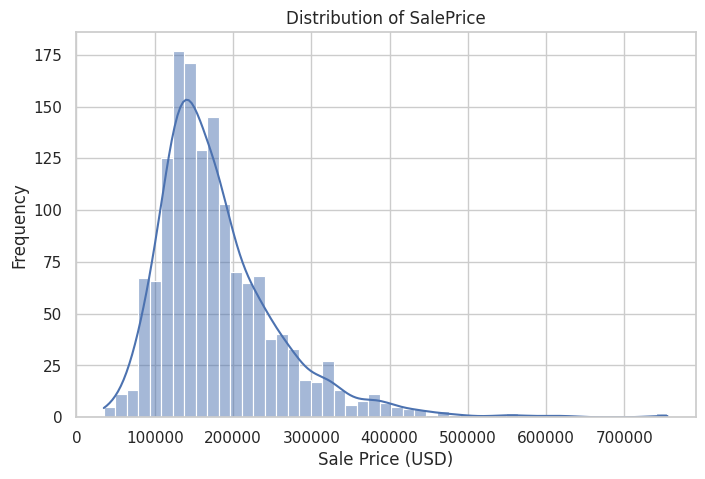

In [34]:
plt.figure(figsize=(8, 5))
sns.histplot(df['SalePrice'], kde=True)
plt.title('Distribution of SalePrice')
plt.xlabel('Sale Price (USD)')
plt.ylabel('Frequency')
plt.show()

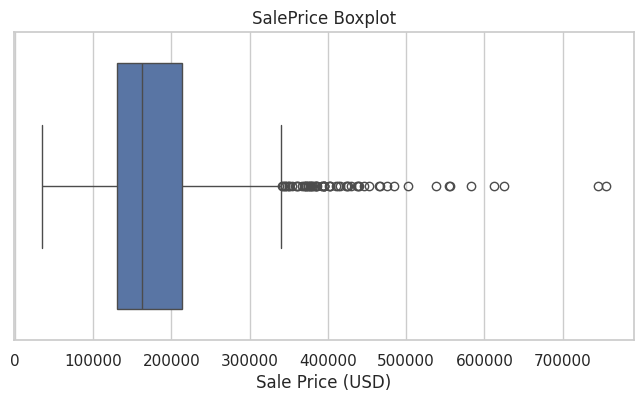

In [35]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['SalePrice'])
plt.title('SalePrice Boxplot')
plt.xlabel('Sale Price (USD)')
plt.show()

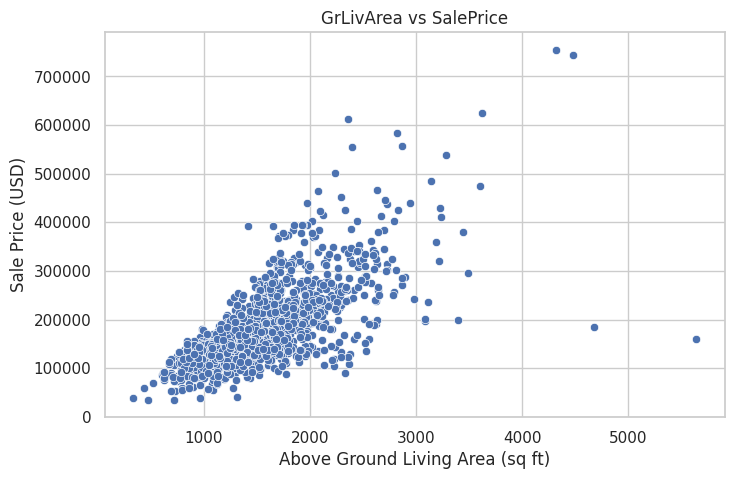

In [36]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='GrLivArea', y='SalePrice')
plt.title('GrLivArea vs SalePrice')
plt.xlabel('Above Ground Living Area (sq ft)')
plt.ylabel('Sale Price (USD)')
plt.show()

In [37]:
outlier_cols = ['GrLivArea', 'LotArea', 'TotalBsmtSF']

outlier_summary = []

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append({
        'Feature': col,
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Outliers Count': count
    })

outlier_summary = pd.DataFrame(outlier_summary)
display(outlier_summary)

,Feature,Lower Bound,Upper Bound,Outliers Count
0,GrLivArea,158.625,2747.625,31
1,LotArea,1481.500,17673.500,69
2,TotalBsmtSF,42.000,2052.000,61


#Outlier Investigation and Treatment

Extreme observations in GrLivArea, LotArea, and TotalBsmtSF were investigated using the IQR method and visual inspection. Unusually large living areas associated with relatively low sale prices were also examined individually.

The identified observations were retained because they represent actual records in the dataset and were not confirmed to be data-entry errors. Removing valid observations could reduce the diversity of properties represented in the dataset and introduce bias.

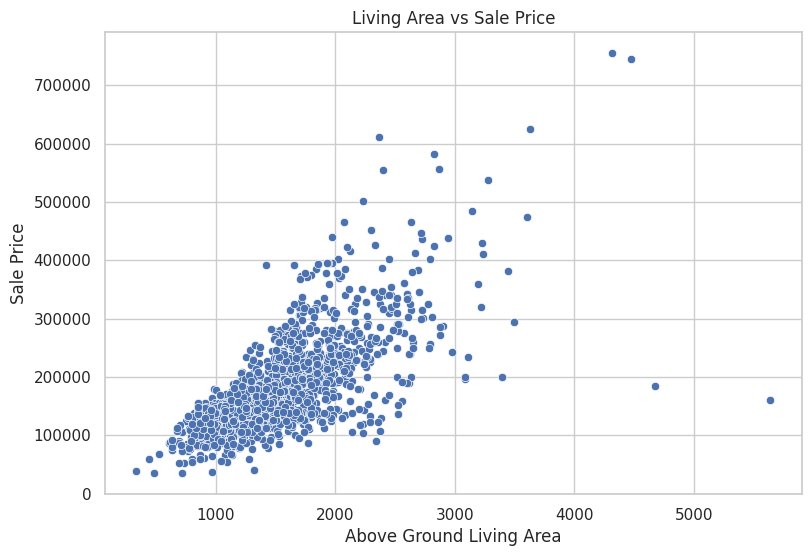

,Id,GrLivArea,SalePrice
523,524,4676,184750
1298,1299,5642,160000


In [38]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='GrLivArea',
    y='SalePrice'
)

plt.title('Living Area vs Sale Price')
plt.xlabel('Above Ground Living Area')
plt.ylabel('Sale Price')
plt.show()

# Inspect unusually large houses with low sale prices
outliers_check = df[
    (df['GrLivArea'] > 4000) &
    (df['SalePrice'] < 300000)
]

display(outliers_check[['Id', 'GrLivArea', 'SalePrice']])

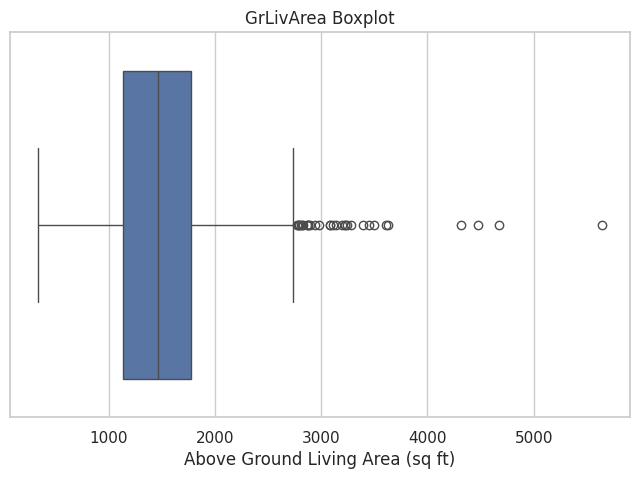

In [39]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['GrLivArea'])
plt.title('GrLivArea Boxplot')
plt.xlabel('Above Ground Living Area (sq ft)')
plt.show()

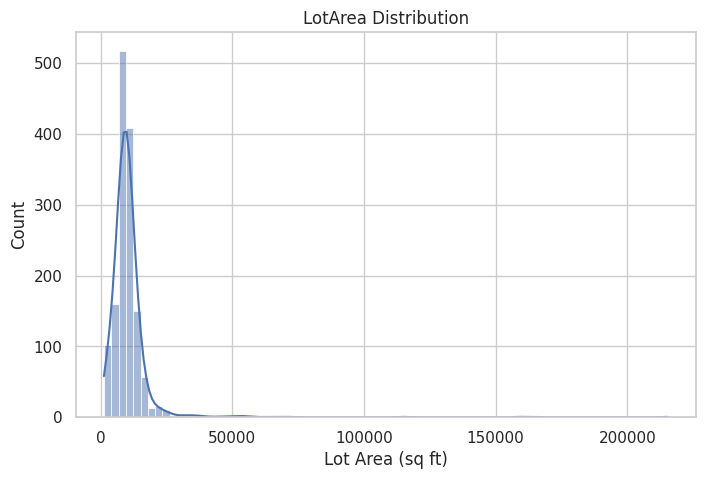

In [40]:
plt.figure(figsize=(8, 5))
sns.histplot(df['LotArea'], kde=True)
plt.title('LotArea Distribution')
plt.xlabel('Lot Area (sq ft)')
plt.show()

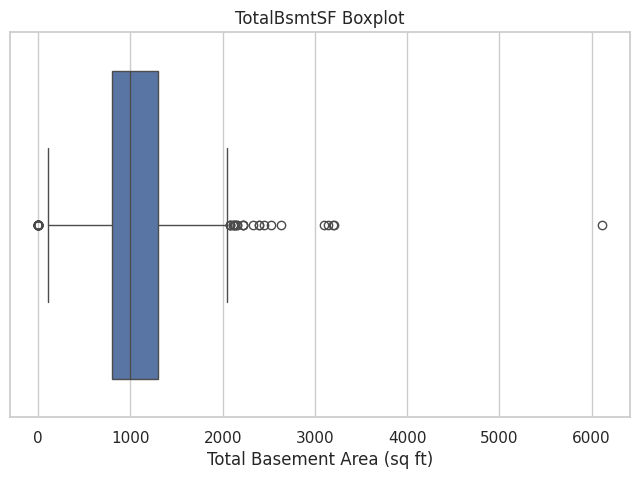

In [41]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['TotalBsmtSF'])
plt.title('TotalBsmtSF Boxplot')
plt.xlabel('Total Basement Area (sq ft)')
plt.show()

In [42]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])

correlation = numeric_df.corr()

correlation['SalePrice'].sort_values(ascending=False)

,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


In [43]:
spearman_corr = numeric_df.corr(method='spearman')

spearman_corr['SalePrice'].sort_values(
    ascending=False
)

,SalePrice
SalePrice,1.000000
OverallQual,0.809829
GrLivArea,0.731310
GarageCars,0.690711
YearBuilt,0.652682
GarageArea,0.649379
FullBath,0.635957
TotalBsmtSF,0.602725
GarageYrBlt,0.593788
1stFlrSF,0.575408


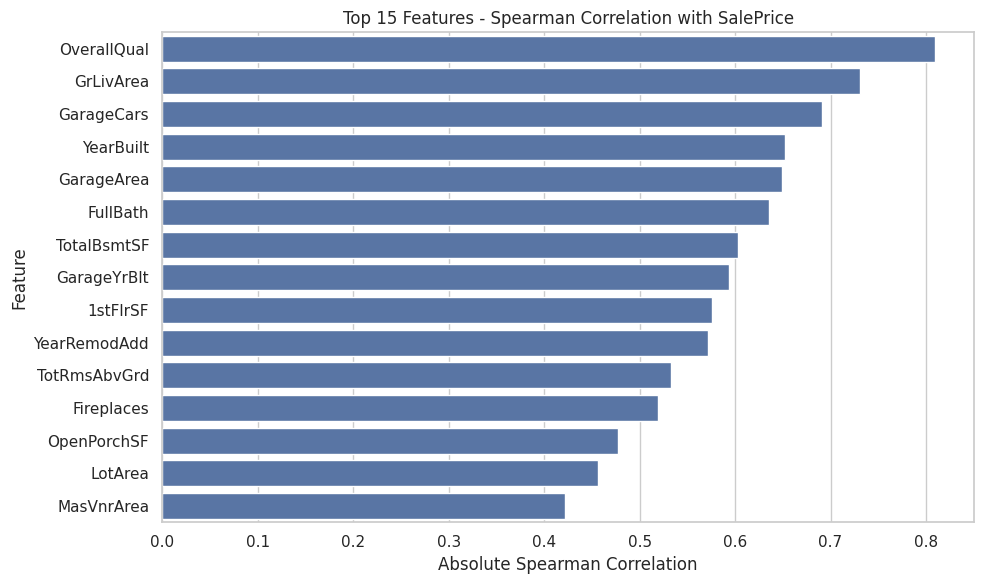

In [44]:
top_spearman = (
    spearman_corr['SalePrice']
    .drop('SalePrice')
    .abs()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_spearman.values,
    y=top_spearman.index
)

plt.title('Top 15 Features - Spearman Correlation with SalePrice')
plt.xlabel('Absolute Spearman Correlation')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [45]:
feature_corr = numeric_df.drop(
    columns=['SalePrice', 'Id']
).corr().abs()

upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    'Feature 1',
    'Feature 2',
    'Absolute Correlation'
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs['Absolute Correlation'] >= 0.80
].sort_values(
    by='Absolute Correlation',
    ascending=False
)

display(high_corr_pairs.round(3))

,Feature 1,Feature 2,Absolute Correlation
575,GarageCars,GarageArea,0.882
183,YearBuilt,GarageYrBlt,0.826
426,GrLivArea,TotRmsAbvGrd,0.825
330,TotalBsmtSF,1stFlrSF,0.820


Multicollinearity Analysis

Highly correlated numerical feature pairs were identified using a correlation threshold of 0.80
 Strong correlations indicate that some predictors may contain overlapping information
  This analysis helps identify potential multicollinearity, particularly among related property size and area features
   The features were retained because they may still provide useful predictive information to the regression models

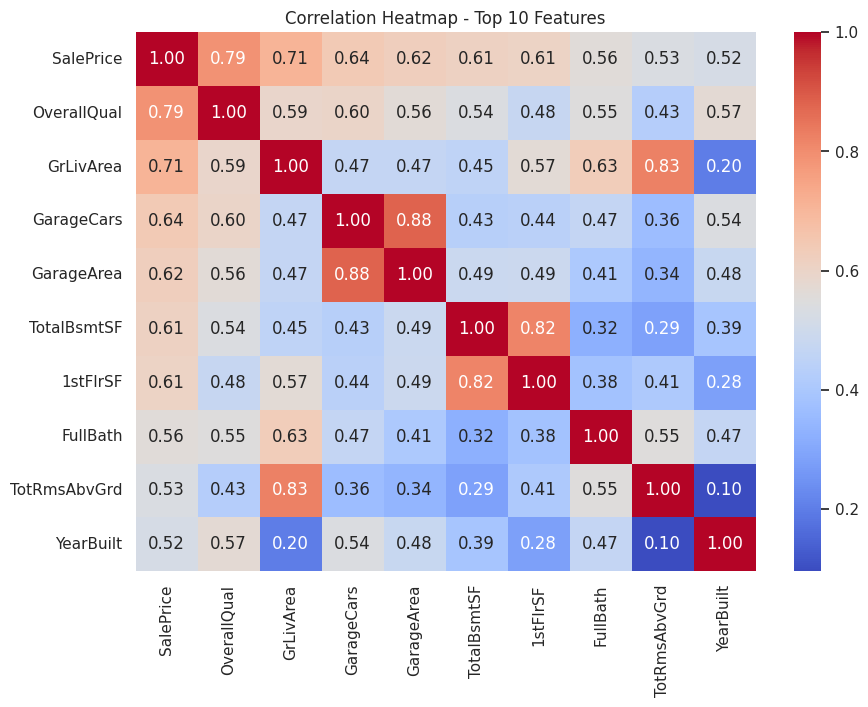

In [46]:
top_features = correlation['SalePrice'].abs().sort_values(
    ascending=False
).head(10).index

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[top_features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap - Top 10 Features')
plt.show()

In [47]:
top_corr = df[top_features].corr()

top_corr.round(2)

,SalePrice,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt
SalePrice,1.00,0.79,0.71,0.64,0.62,0.61,0.61,0.56,0.53,0.52
OverallQual,0.79,1.00,0.59,0.60,0.56,0.54,0.48,0.55,0.43,0.57
GrLivArea,0.71,0.59,1.00,0.47,0.47,0.45,0.57,0.63,0.83,0.20
GarageCars,0.64,0.60,0.47,1.00,0.88,0.43,0.44,0.47,0.36,0.54
GarageArea,0.62,0.56,0.47,0.88,1.00,0.49,0.49,0.41,0.34,0.48
TotalBsmtSF,0.61,0.54,0.45,0.43,0.49,1.00,0.82,0.32,0.29,0.39
1stFlrSF,0.61,0.48,0.57,0.44,0.49,0.82,1.00,0.38,0.41,0.28
FullBath,0.56,0.55,0.63,0.47,0.41,0.32,0.38,1.00,0.55,0.47
TotRmsAbvGrd,0.53,0.43,0.83,0.36,0.34,0.29,0.41,0.55,1.00,0.10
YearBuilt,0.52,0.57,0.20,0.54,0.48,0.39,0.28,0.47,0.10,1.00


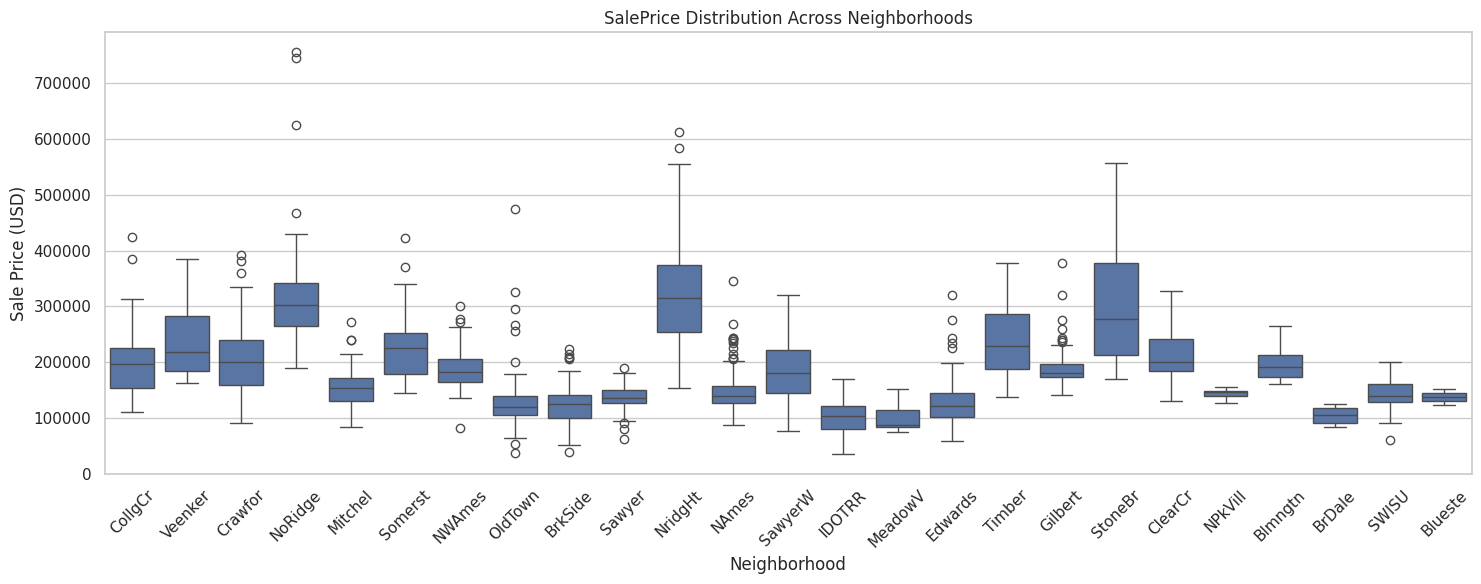

In [49]:
plt.figure(figsize=(15, 6))

sns.boxplot(
    data=df,
    x='Neighborhood',
    y='SalePrice'
)

plt.title('SalePrice Distribution Across Neighborhoods')
plt.xlabel('Neighborhood')
plt.ylabel('Sale Price (USD)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,count,mean
MoSold,,
1,58,183256.26
2,52,177882.00
3,106,183253.92
4,141,171503.26
5,204,172307.27
6,253,177395.74
7,234,186331.19
8,122,184651.83
9,63,195683.21


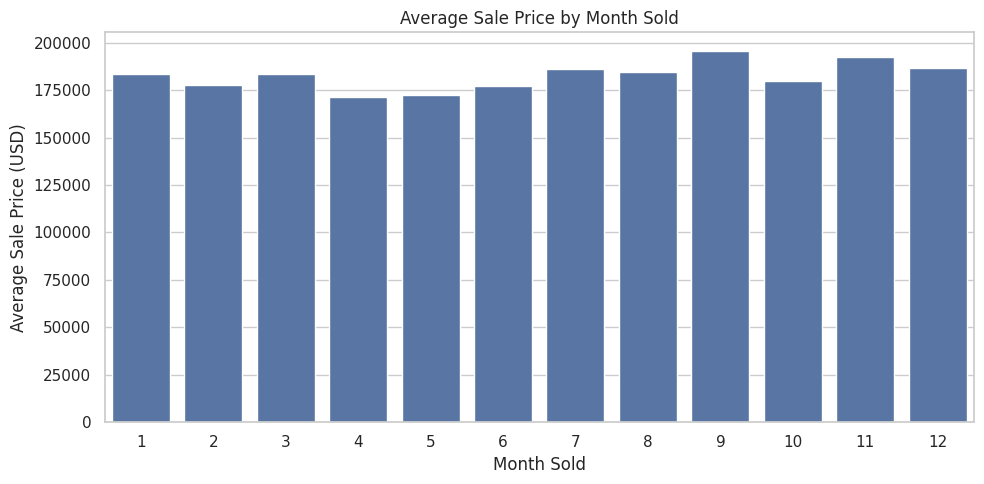

In [74]:
monthly_sales = df.groupby('MoSold')['SalePrice'].agg(
    ['count', 'mean']
)

display(monthly_sales.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    x=monthly_sales.index,
    y=monthly_sales['mean']
)

plt.title('Average Sale Price by Month Sold')
plt.xlabel('Month Sold')
plt.ylabel('Average Sale Price (USD)')
plt.xticks(range(0, 12), range(1, 13))
plt.tight_layout()
plt.show()


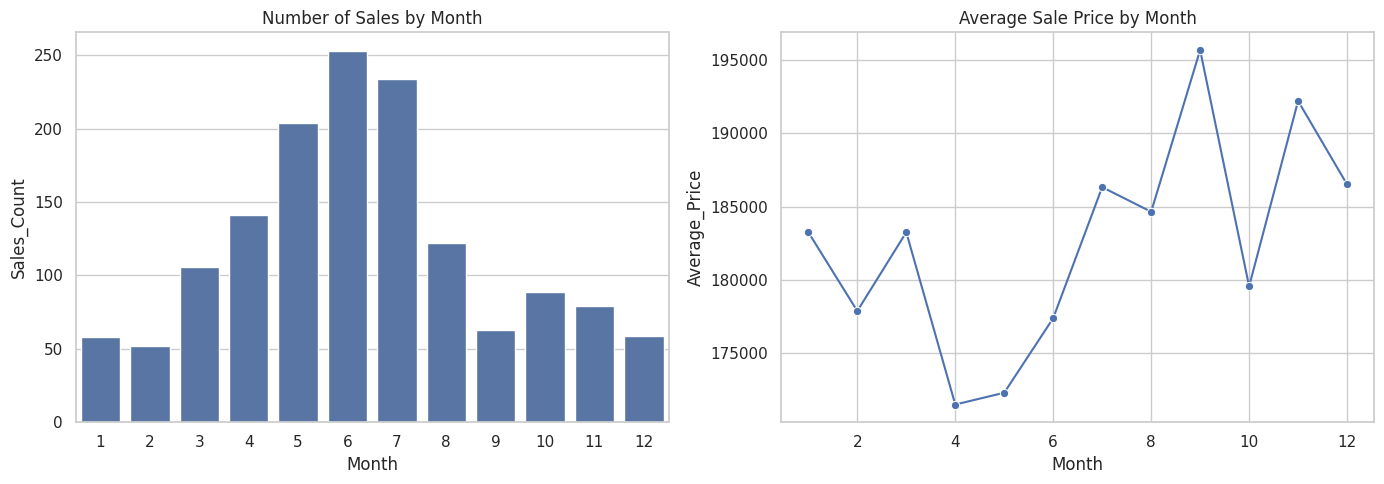

,MoSold,Sales_Count,Average_Price
0,1,58,183256.258621
1,2,52,177882.000000
2,3,106,183253.924528
3,4,141,171503.262411
4,5,204,172307.269608
5,6,253,177395.735178
6,7,234,186331.192308
7,8,122,184651.827869
8,9,63,195683.206349
9,10,89,179563.977528


In [50]:
monthly_sales = df.groupby('MoSold').agg(
    Sales_Count=('SalePrice', 'count'),
    Average_Price=('SalePrice', 'mean')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=monthly_sales, x='MoSold',
            y='Sales_Count', ax=axes[0])

axes[0].set_title('Number of Sales by Month')
axes[0].set_xlabel('Month')

sns.lineplot(data=monthly_sales, x='MoSold',
             y='Average_Price', marker='o', ax=axes[1])

axes[1].set_title('Average Sale Price by Month')
axes[1].set_xlabel('Month')

plt.tight_layout()
plt.show()

display(monthly_sales)

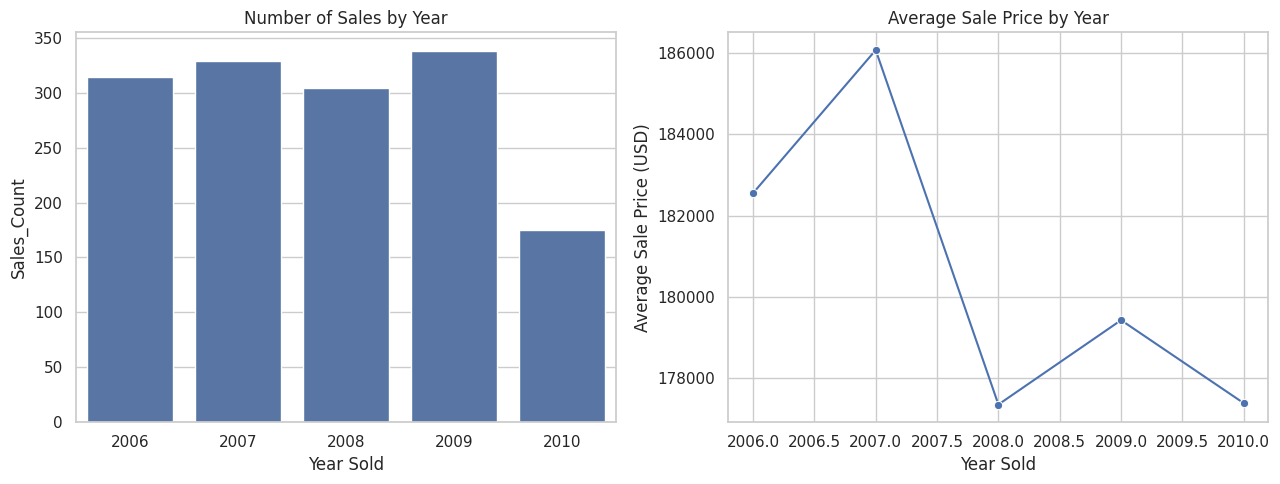

,YrSold,Sales_Count,Average_Price
0,2006,314,182549.458599
1,2007,329,186063.151976
2,2008,304,177360.838816
3,2009,338,179432.103550
4,2010,175,177393.674286


In [51]:
yearly_sales = df.groupby('YrSold').agg(
    Sales_Count=('SalePrice', 'count'),
    Average_Price=('SalePrice', 'mean')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=yearly_sales,
    x='YrSold',
    y='Sales_Count',
    ax=axes[0]
)

axes[0].set_title('Number of Sales by Year')
axes[0].set_xlabel('Year Sold')

sns.lineplot(
    data=yearly_sales,
    x='YrSold',
    y='Average_Price',
    marker='o',
    ax=axes[1]
)

axes[1].set_title('Average Sale Price by Year')
axes[1].set_xlabel('Year Sold')
axes[1].set_ylabel('Average Sale Price (USD)')

plt.tight_layout()
plt.show()

display(yearly_sales)

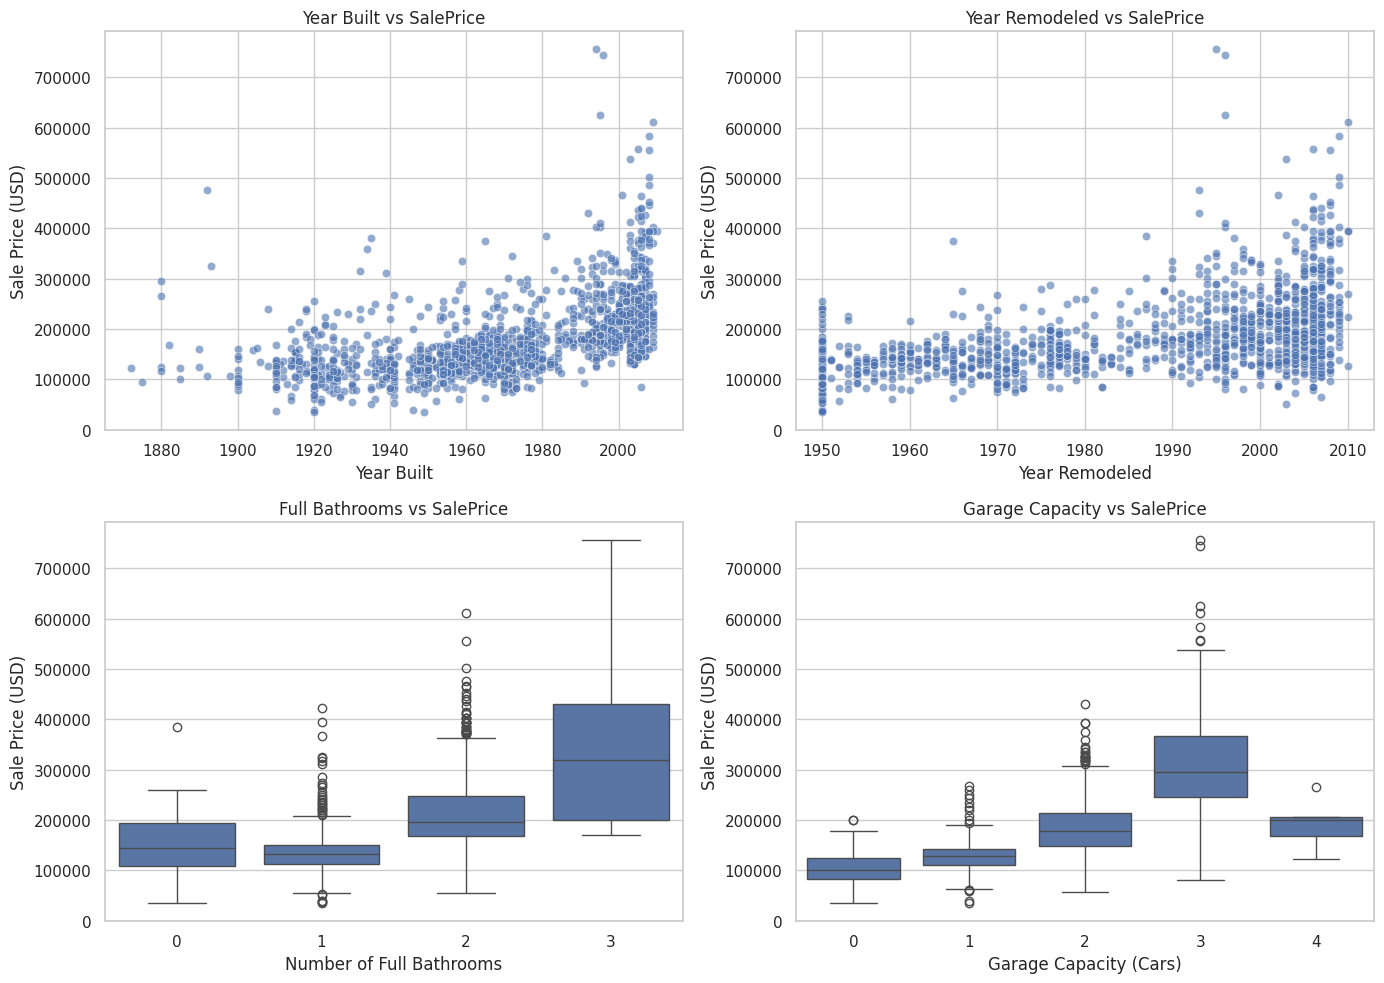

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.scatterplot(
    data=df,
    x='YearBuilt',
    y='SalePrice',
    alpha=0.6,
    ax=axes[0, 0]
)
axes[0, 0].set_title('Year Built vs SalePrice')
axes[0, 0].set_xlabel('Year Built')
axes[0, 0].set_ylabel('Sale Price (USD)')

sns.scatterplot(
    data=df,
    x='YearRemodAdd',
    y='SalePrice',
    alpha=0.6,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Year Remodeled vs SalePrice')
axes[0, 1].set_xlabel('Year Remodeled')
axes[0, 1].set_ylabel('Sale Price (USD)')

sns.boxplot(
    data=df,
    x='FullBath',
    y='SalePrice',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Full Bathrooms vs SalePrice')
axes[1, 0].set_xlabel('Number of Full Bathrooms')
axes[1, 0].set_ylabel('Sale Price (USD)')

sns.boxplot(
    data=df,
    x='GarageCars',
    y='SalePrice',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Garage Capacity vs SalePrice')
axes[1, 1].set_xlabel('Garage Capacity (Cars)')
axes[1, 1].set_ylabel('Sale Price (USD)')

plt.tight_layout()
plt.show()

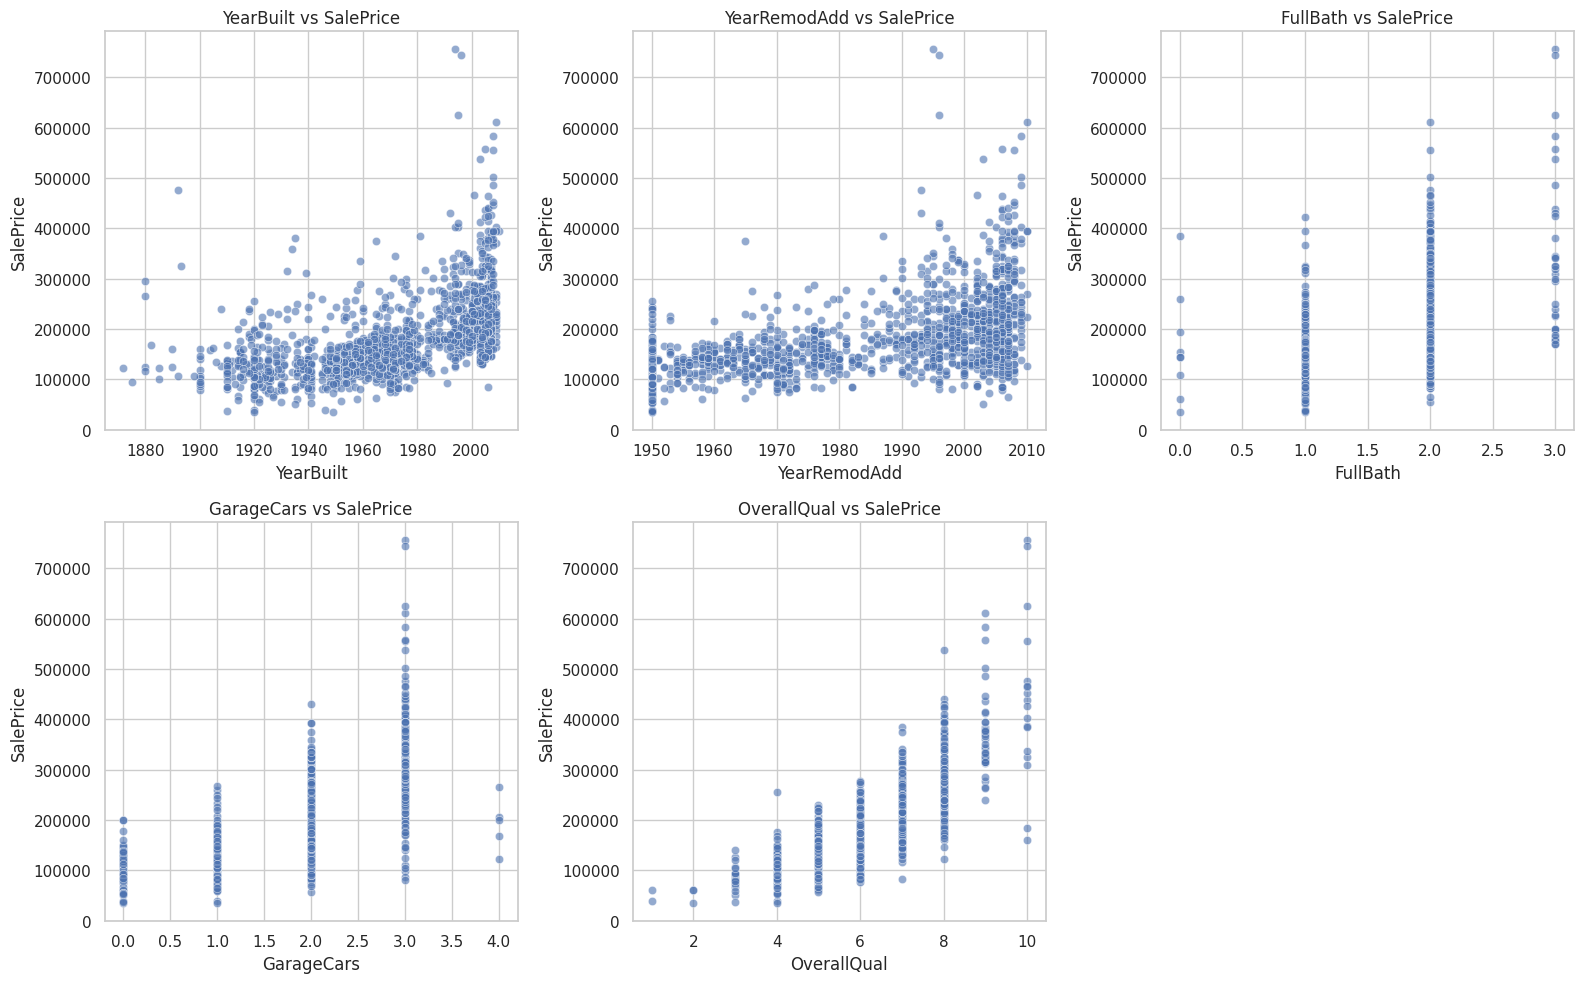

In [54]:
features_to_plot = [
    'YearBuilt',
    'YearRemodAdd',
    'FullBath',
    'GarageCars',
    'OverallQual'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    sns.scatterplot(
        data=df,
        x=col,
        y='SalePrice',
        alpha=0.6,
        ax=axes[i]
    )
    axes[i].set_title(f'{col} vs SalePrice')

axes[-1].axis('off')

plt.tight_layout()
plt.show()

In [55]:
target = 'SalePrice'

X = df.drop(columns=['SalePrice', 'Id']).copy()
y = df[target].copy()

X['MSSubClass'] = X['MSSubClass'].astype(str)


ordinal_category_map = {
    'OverallQual': [str(i) for i in range(1, 11)],
    'OverallCond': [str(i) for i in range(1, 11)],
    'LotShape': ['Reg', 'IR1', 'IR2', 'IR3'],
    'Utilities': ['ELO', 'NoSeWa', 'NoSewr', 'AllPub'],
    'LandSlope': ['Sev', 'Mod', 'Gtl'],
    'ExterQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'ExterCond': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'BsmtQual': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'BsmtCond': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'BsmtExposure': ['None', 'No', 'Mn', 'Av', 'Gd'],
    'BsmtFinType1': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'BsmtFinType2': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'HeatingQC': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'KitchenQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'Functional': ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'],
    'FireplaceQu': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'GarageFinish': ['None', 'Unf', 'RFn', 'Fin'],
    'GarageQual': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'GarageCond': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'PoolQC': ['None', 'Fa', 'TA', 'Gd', 'Ex'],
    'PavedDrive': ['N', 'P', 'Y']
}

ordinal_features = list(ordinal_category_map.keys())


for col in ordinal_features:
    X[col] = X[col].astype(str)

categorical_features = X.select_dtypes(include=['object']).columns.tolist()

nominal_features = [
    col for col in categorical_features
    if col not in ordinal_features
]

numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Numerical feature sub-classification
continuous_features = [
    'LotFrontage', 'LotArea', 'MasVnrArea',
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
    'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
    'LowQualFinSF', 'GrLivArea', 'GarageArea',
    'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch',
    '3SsnPorch', 'ScreenPorch', 'PoolArea'
]

discrete_features = [
    col for col in numeric_features
    if col not in continuous_features
]

print("Numerical features:", len(numeric_features))
print("  Continuous:", len(continuous_features))
print("  Discrete:", len(discrete_features))

print("\nCategorical features:", len(categorical_features))
print("  Ordinal:", len(ordinal_features))
print("  Nominal:", len(nominal_features))

print("\nTotal classified:",
      len(numeric_features) + len(categorical_features))
print("Total predictors:", X.shape[1])

assert len(numeric_features) + len(categorical_features) == X.shape[1]
assert len(set(numeric_features + categorical_features)) == X.shape[1]
assert set(continuous_features).issubset(numeric_features)
assert set(ordinal_features).issubset(categorical_features)

Numerical features: 33
  Continuous: 18
  Discrete: 15

Categorical features: 46
  Ordinal: 21
  Nominal: 25

Total classified: 79
Total predictors: 79


In [56]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1168, 79)
X_test: (292, 79)
y_train: (1168,)
y_test: (292,)


In [57]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
    FunctionTransformer
)

In [58]:
skewed_features = [
    col for col in [
        'LotFrontage', 'LotArea', 'MasVnrArea',
        'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
        'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
        'LowQualFinSF', 'GrLivArea', 'GarageArea',
        'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch',
        '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal'
    ]
    if col in numeric_features
]

other_numeric_features = [
    col for col in numeric_features
    if col not in skewed_features
]

assert (X_train[skewed_features].min() >= 0).all()

print("Skewed numerical features:", len(skewed_features))
print("Other numerical features:", len(other_numeric_features))

Skewed numerical features: 19
Other numerical features: 14


In [59]:
skewed_numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('log', FunctionTransformer(
        np.log1p,
        feature_names_out='one-to-one'
    )),
    ('scaler', StandardScaler())
])


other_numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


ordinal_categories = [
    ordinal_category_map[col] for col in ordinal_features
]

ordinal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='None'
    )),
    ('encoder', OrdinalEncoder(
        categories=ordinal_categories,
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )),
    ('scaler', StandardScaler())
])


nominal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Missing'
    )),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore'
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('skewed_num', skewed_numeric_pipeline, skewed_features),
        ('other_num', other_numeric_pipeline, other_numeric_features),
        ('ordinal', ordinal_pipeline, ordinal_features),
        ('nominal', nominal_pipeline, nominal_features)
    ],
    remainder='drop'
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [60]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

if hasattr(X_train_processed, "toarray"):
    train_array = X_train_processed.toarray()
    test_array = X_test_processed.toarray()
else:
    train_array = X_train_processed
    test_array = X_test_processed

print("Training contains NaN:", np.isnan(train_array).any())
print("Testing contains NaN:", np.isnan(test_array).any())

assert not np.isnan(train_array).any()
assert not np.isnan(test_array).any()

Processed training shape: (1168, 242)
Processed testing shape: (292, 242)
Training contains NaN: False
Testing contains NaN: False


In [61]:
from sklearn.svm import SVR
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_validate, KFold

models = {
    'SVR': SVR(kernel='rbf'),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=100, max_iter=20000),
    'ElasticNet': ElasticNet(
        alpha=0.1,
        l1_ratio=0.5,
        max_iter=20000
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

baseline_pipelines = {
    name: Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    for name, model in models.items()
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

baseline_cv_results = []

for name, pipeline in baseline_pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            'rmse': 'neg_root_mean_squared_error',
            'r2': 'r2'
        },
        return_train_score=True,
        n_jobs=1
    )

    baseline_cv_results.append({
        'Model': name,
        'CV Train RMSE': -scores['train_rmse'].mean(),
        'CV Validation RMSE': -scores['test_rmse'].mean(),
        'CV Validation R2': scores['test_r2'].mean()
    })

baseline_cv_table = pd.DataFrame(baseline_cv_results)

display(
    baseline_cv_table.sort_values(
        'CV Validation RMSE'
    ).round(3)
)

,Model,CV Train RMSE,CV Validation RMSE,CV Validation R2
5,Gradient Boosting,17479.408,27315.047,0.872
4,Random Forest,13974.380,30183.678,0.845
2,Lasso,24552.947,31371.311,0.834
3,ElasticNet,28186.359,31920.787,0.828
1,Ridge,23676.964,32696.217,0.820
0,SVR,78907.754,78826.060,-0.045


In [62]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

svr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', SVR(kernel='rbf'))
])

svr_param_grid = {
    'model__C': [1, 10, 50, 100, 300],
    'model__gamma': ['scale', 0.01, 0.001],
    'model__epsilon': [0.1, 0.2, 0.5]
}

svr_search = RandomizedSearchCV(
    estimator=svr_pipeline,
    param_distributions=svr_param_grid,
    n_iter=12,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    random_state=42,
    n_jobs=1,
    return_train_score=True,
    error_score='raise'
)

svr_search.fit(X_train, y_train)

print("Best SVR Parameters:")
print(svr_search.best_params_)

print("\nBest SVR CV RMSE:")
print(-svr_search.best_score_)

Best SVR Parameters:
{'model__gamma': 0.01, 'model__epsilon': 0.5, 'model__C': 300}

Best SVR CV RMSE:
69518.65173518777


In [63]:
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

ridge_param_grid = {
    'model__alpha': [0.1, 1, 10, 50, 100, 200]
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=1,
    return_train_score=True,
    error_score='raise'
)

ridge_search.fit(X_train, y_train)

print("Best Ridge Parameters:")
print(ridge_search.best_params_)

print("\nBest Ridge CV RMSE:")
print(-ridge_search.best_score_)

Best Ridge Parameters:
{'model__alpha': 10}

Best Ridge CV RMSE:
31712.321783831703


In [65]:
final_models = {
    'SVR Tuned': svr_search.best_estimator_,
    'Ridge Tuned': ridge_search.best_estimator_
}


for name in [
    'Lasso',
    'ElasticNet',
    'Random Forest',
    'Gradient Boosting'
]:
    final_models[name] = baseline_pipelines[name]


for name, model in final_models.items():
    if name not in ['SVR Tuned', 'Ridge Tuned']:
        model.fit(X_train, y_train)

print("All final models are ready.")

All final models are ready.


In [66]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def calculate_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred)
    }

evaluation_results = []

for name, model in final_models.items():

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    train_metrics = calculate_metrics(
        y_train, train_predictions
    )

    test_metrics = calculate_metrics(
        y_test, test_predictions
    )

    evaluation_results.append({
        'Model': name,

        'Train MAE': train_metrics['MAE'],
        'Test MAE': test_metrics['MAE'],

        'Train MSE': train_metrics['MSE'],
        'Test MSE': test_metrics['MSE'],

        'Train RMSE': train_metrics['RMSE'],
        'Test RMSE': test_metrics['RMSE'],

        'Train R2': train_metrics['R2'],
        'Test R2': test_metrics['R2']
    })

results_df = pd.DataFrame(evaluation_results)

results_df = results_df.sort_values(
    by='Test RMSE'
).reset_index(drop=True)

display(results_df.round(3))

,Model,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2
0,Random Forest,7217.135,17270.472,1.756228e+08,8.147890e+08,13252.277,28544.509,0.971,0.894
1,Gradient Boosting,13103.975,18573.831,3.291213e+08,8.706493e+08,18141.699,29506.768,0.945,0.886
2,Lasso,17213.391,19488.702,6.425997e+08,1.043216e+09,25349.549,32298.848,0.892,0.864
3,Ridge Tuned,17239.892,19639.711,7.008604e+08,1.111952e+09,26473.768,33345.948,0.882,0.855
4,ElasticNet,17892.908,20071.407,8.216322e+08,1.206354e+09,28664.128,34732.614,0.862,0.843
5,SVR Tuned,42615.824,46308.087,4.596038e+09,5.909113e+09,67794.084,76870.754,0.229,0.230


In [67]:
# Cross-validation results for the tuned models
svr_best_index = svr_search.best_index_
ridge_best_index = ridge_search.best_index_

tuned_cv_results = pd.DataFrame([
    {
        'Model': 'SVR Tuned',
        'CV Train RMSE': -svr_search.cv_results_['mean_train_score'][svr_best_index],
        'CV Validation RMSE': -svr_search.best_score_
    },
    {
        'Model': 'Ridge Tuned',
        'CV Train RMSE': -ridge_search.cv_results_['mean_train_score'][ridge_best_index],
        'CV Validation RMSE': -ridge_search.best_score_
    }
])

# Keep the untuned models from the baseline comparison
other_cv_results = baseline_cv_table[
    baseline_cv_table['Model'].isin([
        'Lasso',
        'ElasticNet',
        'Random Forest',
        'Gradient Boosting'
    ])
][['Model', 'CV Train RMSE', 'CV Validation RMSE']]

cv_comparison = pd.concat(
    [tuned_cv_results, other_cv_results],
    ignore_index=True
)

cv_comparison = cv_comparison.sort_values(
    'CV Validation RMSE'
).reset_index(drop=True)

display(cv_comparison.round(3))

,Model,CV Train RMSE,CV Validation RMSE
0,Gradient Boosting,17479.408,27315.047
1,Random Forest,13974.380,30183.678
2,Lasso,24552.947,31371.311
3,Ridge Tuned,26037.508,31712.322
4,ElasticNet,28186.359,31920.787
5,SVR Tuned,69491.322,69518.652


In [68]:
results_df['RMSE Gap'] = (
    results_df['Test RMSE'] - results_df['Train RMSE']
)

results_df['Generalization Gap (%)'] = (
    results_df['RMSE Gap'] /
    results_df['Train RMSE']
) * 100

display(
    results_df[
        ['Model', 'Train RMSE', 'Test RMSE',
         'RMSE Gap', 'Generalization Gap (%)']
    ].round(3)
)

,Model,Train RMSE,Test RMSE,RMSE Gap,Generalization Gap (%)
0,Random Forest,13252.277,28544.509,15292.232,115.393
1,Gradient Boosting,18141.699,29506.768,11365.068,62.646
2,Lasso,25349.549,32298.848,6949.298,27.414
3,Ridge Tuned,26473.768,33345.948,6872.181,25.958
4,ElasticNet,28664.128,34732.614,6068.487,21.171
5,SVR Tuned,67794.084,76870.754,9076.671,13.389


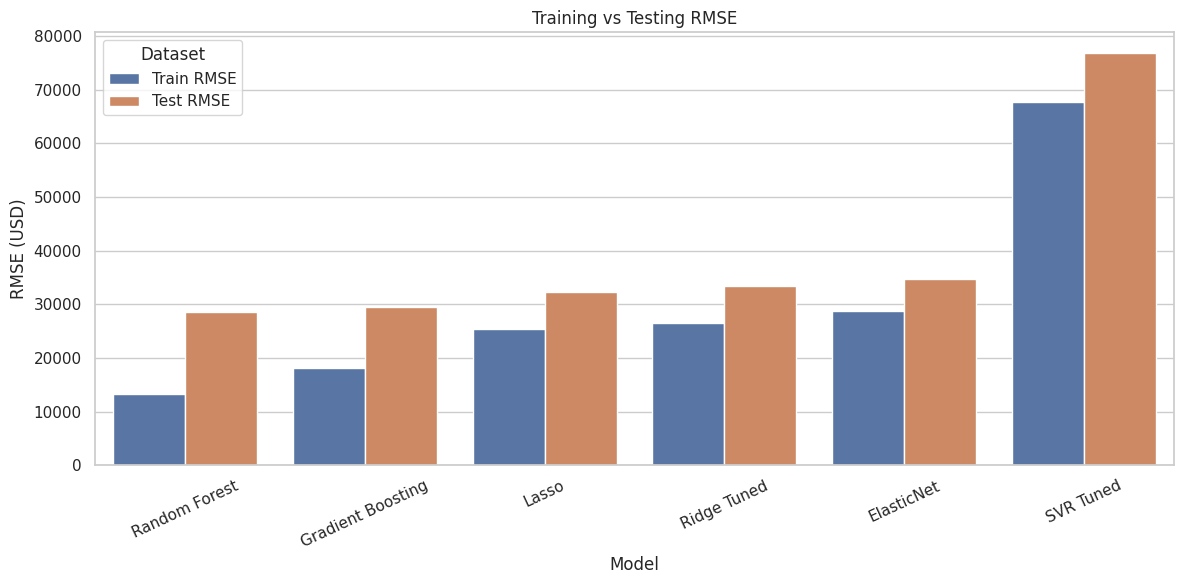

In [69]:
plot_data = results_df.melt(
    id_vars='Model',
    value_vars=['Train RMSE', 'Test RMSE'],
    var_name='Dataset',
    value_name='RMSE'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    x='Model',
    y='RMSE',
    hue='Dataset'
)

plt.title('Training vs Testing RMSE')
plt.xlabel('Model')
plt.ylabel('RMSE (USD)')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [70]:
from sklearn.inspection import permutation_importance

# Select the best model based on CV validation RMSE
best_model_name = cv_comparison.iloc[0]['Model']
best_model = final_models[best_model_name]

print("Best model based on Cross-Validation:", best_model_name)

permutation_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring='neg_root_mean_squared_error',
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': permutation_result.importances_mean,
    'Std': permutation_result.importances_std
})

importance_df = importance_df.sort_values(
    'Importance',
    ascending=False
)

display(importance_df.head(15).round(4))

Best model based on Cross-Validation: Gradient Boosting


,Feature,Importance,Std
16,OverallQual,20332.5260,917.7867
45,GrLivArea,15440.8190,1071.8696
43,2ndFlrSF,3681.7260,287.5334
37,TotalBsmtSF,2815.6884,524.7170
60,GarageCars,2321.0168,126.6142
29,BsmtQual,1967.4302,164.8599
33,BsmtFinSF1,1911.1099,512.0699
52,KitchenQual,1548.6641,263.9377
3,LotArea,1511.2048,264.1799
42,1stFlrSF,989.8850,334.8716


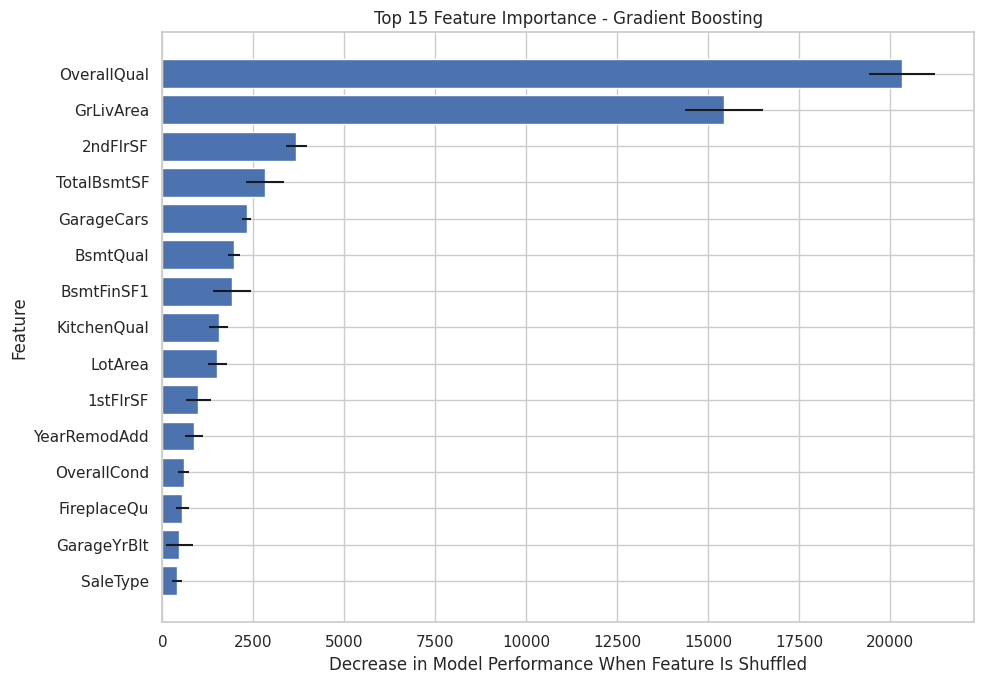

In [71]:
top_importance = importance_df.head(15).sort_values(
    'Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_importance['Feature'],
    top_importance['Importance'],
    xerr=top_importance['Std']
)

plt.title(f'Top 15 Feature Importance - {best_model_name}')
plt.xlabel('Decrease in Model Performance When Feature Is Shuffled')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

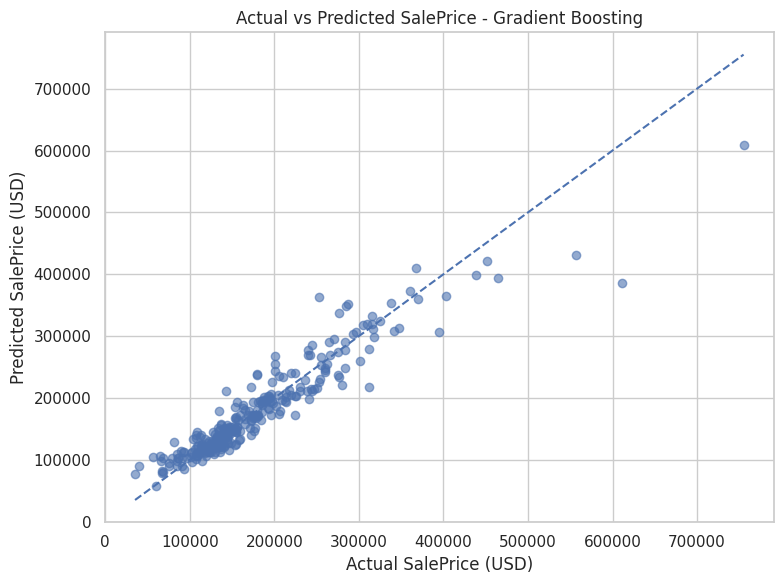

In [72]:
best_predictions = best_model.predict(X_test)

min_value = min(
    y_test.min(),
    best_predictions.min()
)

max_value = max(
    y_test.max(),
    best_predictions.max()
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.6
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.title(f'Actual vs Predicted SalePrice - {best_model_name}')
plt.xlabel('Actual SalePrice (USD)')
plt.ylabel('Predicted SalePrice (USD)')
plt.tight_layout()
plt.show()

In [73]:
print("FINAL MODEL COMPARISON")
display(
    results_df[
        [
            'Model',
            'Train MAE', 'Test MAE',
            'Train RMSE', 'Test RMSE',
            'Train R2', 'Test R2'
        ]
    ].round(3)
)

print("\nBest model based on Cross-Validation:")
print(best_model_name)

print("\nBest model CV RMSE:")
print(round(cv_comparison.iloc[0]['CV Validation RMSE'], 3))

print("\nBest model Test RMSE:")
print(round(
    results_df.loc[
        results_df['Model'] == best_model_name,
        'Test RMSE'
    ].iloc[0],
    3
))

FINAL MODEL COMPARISON


,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Random Forest,7217.135,17270.472,13252.277,28544.509,0.971,0.894
1,Gradient Boosting,13103.975,18573.831,18141.699,29506.768,0.945,0.886
2,Lasso,17213.391,19488.702,25349.549,32298.848,0.892,0.864
3,Ridge Tuned,17239.892,19639.711,26473.768,33345.948,0.882,0.855
4,ElasticNet,17892.908,20071.407,28664.128,34732.614,0.862,0.843
5,SVR Tuned,42615.824,46308.087,67794.084,76870.754,0.229,0.230



Best model based on Cross-Validation:
Gradient Boosting

Best model CV RMSE:
27315.047

Best model Test RMSE:
29506.768


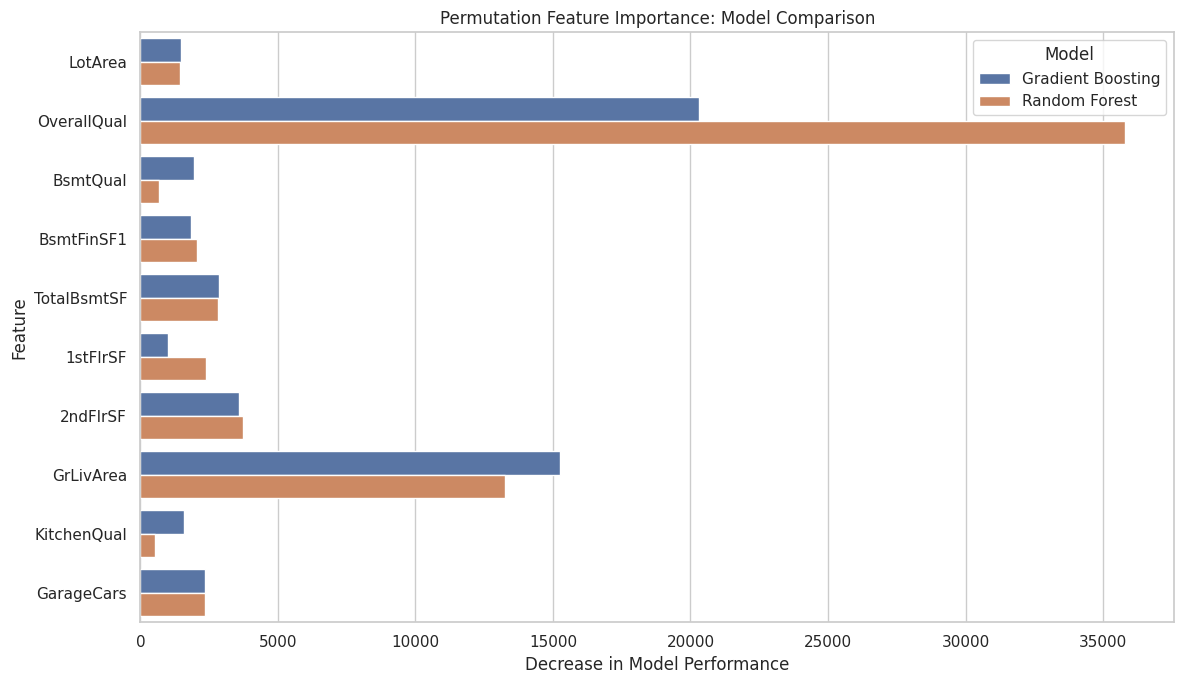

In [75]:

from sklearn.inspection import permutation_importance

models_to_compare = {
    'Gradient Boosting': final_models['Gradient Boosting'],
    'Random Forest': final_models['Random Forest']
}

importance_results = []

for model_name, model in models_to_compare.items():
    result = permutation_importance(
        model,
        X_test,
        y_test,
        n_repeats=10,
        random_state=42,
        scoring='neg_root_mean_squared_error'
    )

    model_importance = pd.DataFrame({
        'Feature': X_test.columns,
        'Importance': result.importances_mean,
        'Model': model_name
    })

    importance_results.append(model_importance)

importance_comparison = pd.concat(
    importance_results,
    ignore_index=True
)

top_features = (
    importance_comparison
    .groupby('Feature')['Importance']
    .max()
    .nlargest(10)
    .index
)

comparison_plot = importance_comparison[
    importance_comparison['Feature'].isin(top_features)
]

plt.figure(figsize=(12, 7))
sns.barplot(
    data=comparison_plot,
    x='Importance',
    y='Feature',
    hue='Model'
)

plt.title('Permutation Feature Importance: Model Comparison')
plt.xlabel('Decrease in Model Performance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


Final Results and Discussion

Gradient Boosting achieved the best cross-validation RMSE ($27,315), while Random Forest achieved the best test performance (RMSE $28,545, R² 0.894), with a larger overfitting gap.

Gradient Boosting was selected based on cross-validation results. Permutation importance showed that OverallQual and GrLivArea`were the most influential features.

Overall, ensemble models performed best, with Gradient Boosting providing the strongest validation performance and Random Forest the strongest test performance. The use of pipelines and cross-validation helped reduce data leakage and ensure reliable evaluation.


References

1.   https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques

2. https://scikit-learn.org/stable/modules/compose.html

3.  https://scikit-learn.org/stable/modules/model_evaluation.html

4.   https://scikit-learn.org/stable/modules/permutation_importance.html

